# Chapter 22 | Complete worked solutions

*Object Detection and Segmentation*

All eleven exercises are solved here. Trace boxes and mask pixels, distinguish
training assignment from ranked evaluation, and design prompting and coordinate
checks. The examples run on CPU without a model or dataset download. Three plots
show mask overlap, precision envelopes and detection errors. The written PDF
preserves all explanations and plots; the notebook PDF adds code and outputs.
These are teaching fixtures, not benchmark results for a trained detector.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch22_detection"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from examples.ch22_detection.model import box_iou, mask_iou, match_queries, all_points_ap
print("NumPy",np.__version__,"| Matplotlib",matplotlib.__version__)

NumPy 2.5.4 | Matplotlib 3.11.2


## 1. Compare two boxes

The box $A=(1,1,4,3)$ has width $4-1=3$ and height $3-1=2$, hence
area 6. The box $B=(2,0,5,2)$ also has width 3 and height 2, hence area 6.
Coordinates mark edges; no extra unit is added at either endpoint.

The intersection starts at the larger left edge and ends at the smaller
right edge, giving horizontal interval $[2,4]$ of width 2. Vertically it
runs from 1 to 2, giving height 1. Its area is 2. Adding the two box areas
counts the overlap twice, so subtract it once: union $=6+6-2=10$ and
IoU $=2/10=1/5$.

Moving B right by one changes both x edges: $B'=(3,0,6,2)$.
Its area stays 6. The overlap now has width 1 and height 1, hence area 1.
The union is $6+6-1=11$, giving IoU $1/11$. Translation changed the
intersection, not the individual box areas.

In [2]:
a=(1,1,4,3);b=(2,0,5,2);moved=(3,0,6,2)
for name,other,intersection in [("Original B",b,2),("B moved right",moved,1)]:
    union=6+6-intersection
    observed=box_iou(a,other)
    np.testing.assert_allclose(observed,intersection/union)
    print(name,": areas 6, 6; intersection",intersection,"; union",union,"; IoU",round(observed,6))

Original B : areas 6, 6; intersection 2 ; union 10 ; IoU 0.2
B moved right : areas 6, 6; intersection 1 ; union 11 ; IoU 0.090909


## 2. Count shared pixels

Use zero-based (row, column) coordinates. Rows increase downward and columns
rightward; this order differs from an $(x,y)$ point. The two masks are
$$
 A=\begin{bmatrix}1&1&0\\0&1&0\\0&0&0\end{bmatrix},\qquad
 B=\begin{bmatrix}0&1&0\\0&1&1\\0&0&1\end{bmatrix}.
$$
The shared pixels are $(0,1)$ and $(1,1)$, so the intersection contains two
pixels. The union contains $(0,0)$, $(0,1)$, $(1,1)$, $(1,2)$ and $(2,2)$,
five pixels in total. Equivalently, $|A\cup B|=3+4-2=5$. Their IoU is $2/5$.
The plot displays each mask and both set operations. A dark cell is foreground;
the number inside each cell makes the count explicit.

Intersection: 2 ; union: 5 ; IoU: 0.4


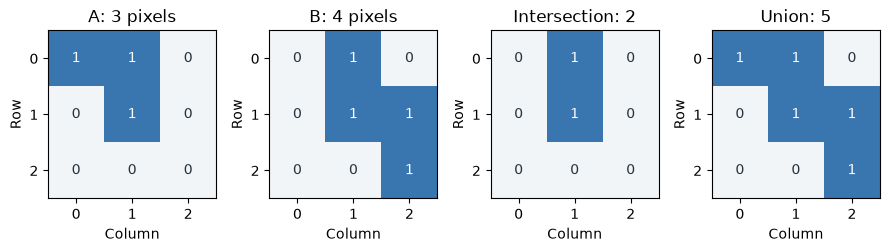

In [3]:
mask_a=np.zeros((3,3),dtype=bool);mask_b=mask_a.copy()
for point in [(0,0),(0,1),(1,1)]:mask_a[point]=True
for point in [(0,1),(1,1),(1,2),(2,2)]:mask_b[point]=True
intersection=mask_a & mask_b;union=mask_a | mask_b
assert intersection.sum()==2 and union.sum()==5
assert mask_iou(mask_a,mask_b)==2/5
print("Intersection:",intersection.sum(),"; union:",union.sum(),"; IoU:",mask_iou(mask_a,mask_b))
fig,axes=plt.subplots(1,4,figsize=(9,2.8))
from matplotlib.colors import ListedColormap
for ax,grid,title in zip(axes,[mask_a,mask_b,intersection,union],["A: 3 pixels","B: 4 pixels","Intersection: 2","Union: 5"]):
    ax.imshow(grid,cmap=ListedColormap(["#F2F5F7","#3976AF"]),vmin=0,vmax=1)
    for (rr,cc),value in np.ndenumerate(grid):
        ax.text(cc,rr,int(value),ha="center",va="center",color="white" if value else "#26323D")
    ax.set(xticks=range(3),yticks=range(3),xlabel="Column",ylabel="Row",title=title)
fig.tight_layout();plt.show()

## 3. Make a one-to-one assignment

The rows are Q1, Q2, Q3 and the columns are objects A, B. Choosing the
minimum independently in each column would select Q1 twice, with apparent
cost $2+1=3$. That is invalid: one query cannot stand for both objects.

There are $3\times2=6$ valid assignments. Choose a query for A, then a
different query for B:

| Query for A | Query for B | Total cost |
|---|---|---|
| Q1 | Q2 | $2+5=7$ |
| Q1 | Q3 | $2+2=4$ |
| Q2 | Q1 | $3+1=4$ |
| Q2 | Q3 | $3+2=5$ |
| Q3 | Q1 | $4+1=5$ |
| Q3 | Q2 | $4+5=9$ |

There are **two minima**, both of cost 4. Q1 for A and Q3 for B leaves
Q2 unmatched. Q2 for A and Q1 for B leaves Q3 unmatched. Either is a
valid optimal one-to-one assignment. The selected unmatched query receives
the no-object class in training. One-to-one describes the constraint;
it does not assert that the optimum is unique. Exercise 7 examines the
helper's deterministic tie rule.

In [4]:
from itertools import permutations
cost=np.array([[2,1],[3,5],[4,2]])
totals={pair:sum(cost[q,t].item() for t,q in enumerate(pair))
        for pair in permutations(range(3),2)}
best=min(totals.values())
optima=[pair for pair,value in totals.items() if value==best]
assert optima==[(0,2),(1,0)] and best==4
for qa,qb in optima:
    unmatched=({0,1,2}-{qa,qb}).pop()
    print(f"A <- Q{qa+1}, B <- Q{qb+1}; unmatched Q{unmatched+1}; cost {best}")

A <- Q1, B <- Q3; unmatched Q2; cost 4
A <- Q2, B <- Q1; unmatched Q3; cost 4


## 4. Track precision and recall

There are three annotated objects. A true positive increases the matched
count; a false positive increases only the number of predictions. At each
rank, divide matches so far by predictions seen for precision, and by three
for recall:

| Rank | Outcome | Matches | Precision | Recall |
|---|---|---|---|---|
| 1 | False positive | 0 | 0 | 0 |
| 2 | True positive | 1 | $1/2$ | $1/3$ |
| 3 | True positive | 2 | $2/3$ | $2/3$ |
| 4 | False positive | 2 | $1/2$ | $2/3$ |

The maximum recall is $2/3$. Keeping all four predictions still leaves one
object unmatched. Full recall requires a new qualifying detection, not merely
a lower confidence cutoff on this unchanged list.

Scanning precision backward gives the envelope values $(2/3,2/3,2/3,1/2)$.
Recall increases are $(0,1/3,1/3,0)$, so
$$
 \mathrm{AP}=0(2/3)+(1/3)(2/3)+(1/3)(2/3)+0(1/2)=4/9.
$$
The remaining recall interval from $2/3$ to 1 contributes zero. Dividing the
area by the attained recall would instead give $2/3$, which is not this AP.
The last false positive lowers final precision but adds no new recall width;
removing it leaves the interpolated AP unchanged.

In [5]:
flags=np.array([False,True,True,False]);cum=np.cumsum(flags)
precision=cum/np.arange(1,5);recall=cum/3
envelope=np.maximum.accumulate(precision[::-1])[::-1]
ap=all_points_ap(precision,recall)
np.testing.assert_allclose(ap,4/9)
np.testing.assert_allclose(all_points_ap(precision[:-1],recall[:-1]),ap)
print("Precision:",precision.round(4));print("Recall:",recall.round(4))
print("Envelope:",envelope.round(4));print("All-points AP:",round(ap,6))

Precision: [0.     0.5    0.6667 0.5   ]
Recall: [0.     0.3333 0.6667 0.6667]
Envelope: [0.6667 0.6667 0.6667 0.5   ]
All-points AP: 0.444444


## 5. Check touching edges

Place box A at $(0,0,2,3)$ and box B at $(2,0,4,3)$. They share
the vertical edge at $x=2$. Move B a quarter unit left to
$(1.75,0,3.75,3)$, and the shared region becomes a thin rectangle.

The coordinates $(x_0,y_0,x_1,y_1)$ mark continuous edges. The width is
$x_1-x_0$, and the height is $y_1-y_0$. Both boxes have area $2\cdot3=6$
before and after the shift. The intersection width comes from the
smaller right edge minus the larger left edge, clamped at zero. The
intersection height is $3$ in both cases.


When the edges touch, the overlap width is $2-2=0$. The common
  edge has zero area, so the union is $6+6=12$ and IoU is $0/12=0$.

After the shift, the overlap width is $2-1.75=0.25$. The intersection
  area is $0.25\cdot3=0.75$, and the union area is $6+6-0.75=11.25$.
  The IoU is $0.75/11.25=1/15\approx0.066667$.

In [6]:
from examples.ch22_detection.model import box_iou

box_a = (0, 0, 2, 3)
box_b_touching = (2, 0, 4, 3)
box_b_shifted = (2 - 0.25, 0, 4 - 0.25, 3)

touching_iou = box_iou(box_a, box_b_touching)
shifted_iou = box_iou(box_a, box_b_shifted)

# Check the implementation against the areas from the hand calculation.
cases = [
    ("Touching", touching_iou, 0 * 3),
    ("Shifted left", shifted_iou, (2 - 1.75) * 3),
]
print(f"{'Case':<14} {'Intersection':>12} {'Union':>7} {'IoU':>10}")
for label, observed_iou, intersection in cases:
    union = 6 + 6 - intersection
    np.testing.assert_allclose(observed_iou, intersection / union)
    print(f"{label:<14} {intersection:>12.2f} {union:>7.2f} "
          f"{observed_iou:>10.6f}")

Case           Intersection   Union        IoU
Touching               0.00   12.00   0.000000
Shifted left           0.75   11.25   0.066667


The shift leaves both widths at two units and creates a positive
overlap of exactly a quarter unit in width. The continuous-edge
convention treats each endpoint as a boundary, so the width formula
has no extra unit for an endpoint.

## 6. Inspect an empty union (optional)

Start with two $3\times3$ Boolean masks on the same pixel grid.
Every entry is `False`, so neither mask marks any foreground.
Add a foreground pixel at row 1, column 1 of the second mask.

The intersection counts pixels marked by both masks. The union counts
pixels marked by either mask, counting a shared pixel once.


With both masks empty, the intersection and union both contain
  zero pixels. The ratio $0/0$ is undefined, and `mask_iou` returns
  `None`.

With one marked pixel in the second mask, the intersection is
  still empty and the union contains that one pixel. The ratio
  $0/1=0$ is a defined score for zero shared foreground.

In [7]:
from examples.ch22_detection.model import mask_iou

empty_mask_a = np.zeros((3, 3), dtype=bool)
empty_mask_b = np.zeros((3, 3), dtype=bool)
both_empty_iou = mask_iou(empty_mask_a, empty_mask_b)

one_pixel_mask_b = empty_mask_b.copy()
one_pixel_mask_b[1, 1] = True
one_pixel_iou = mask_iou(empty_mask_a, one_pixel_mask_b)

# A is empty, so B supplies every pixel in the union.
empty_union_count = np.count_nonzero(empty_mask_b)
one_pixel_union_count = np.count_nonzero(one_pixel_mask_b)
assert empty_union_count == 0 and both_empty_iou is None
assert one_pixel_union_count == 1 and one_pixel_iou == 0 / 1

print(f"{'Case':<14} {'Intersection':>12} {'Union':>7} {'IoU':>8}")
print(f"{'Both empty':<14} {0:>12} {empty_union_count:>7} "
      f"{str(both_empty_iou):>8}")
print(f"{'One pixel':<14} {0:>12} {one_pixel_union_count:>7} "
      f"{one_pixel_iou:>8.1f}")

Case           Intersection   Union      IoU
Both empty                0       0     None
One pixel                 0       1      0.0


The first pair has no foreground over which to measure overlap.
The second pair does have foreground to compare, and the empty
first mask shares none of it. The two return values preserve that
difference.

## 7. Inspect matching indices

Use the three query rows from Exercise 3. The rows are Q1, Q2, and Q3,
in that order. The columns are targets A and B. Both column minima
pick Q1, for costs 2 and 1, so using those two minima would assign the
same query twice.

Try each pair of distinct queries. The total for Q1 with A and Q3
with B, for example, is $2+2=4$. Increasing entry `[0, 1]` from 1 to
5 changes only the totals that pair Q1 with B.

| Query for A | Query for B | Original total | Revised total |
| --- | --- | ---: | ---: |
| Q1 | Q2 | 7 | 7 |
| Q1 | Q3 | 4 | 4 |
| Q2 | Q1 | 4 | 8 |
| Q2 | Q3 | 5 | 5 |
| Q3 | Q1 | 5 | 9 |
| Q3 | Q2 | 9 | 9 |

The original matrix has two equally good assignments. The helper
tries query indices in ascending order for A, then for B. It
keeps the first minimum, Q1 for A and Q3 for B, and reports
zero-based `(query, target)` pairs, so this is `((0, 0), (2, 1))` and query
index 1 (Q2) is unmatched. The other minimum, Q2 for A and Q1 for
B, rises from 4 to 8. The returned assignment stays at cost 4
and becomes the unique minimum.

In [8]:
from examples.ch22_detection.model import match_queries

original_cost = np.array([[2, 1], [3, 5], [4, 2]])
revised_cost = original_cost.copy()
revised_cost[0, 1] += 4

original_match = match_queries(original_cost)
revised_match = match_queries(revised_cost)

for label, result in (
    ("Original", original_match), ("Revised", revised_match)
):
    pairs, unmatched, total = result
    print(f"{label} pairs {pairs}")
    print(f"  Unmatched {unmatched}    Total cost {total}")

expected_match = (((0, 0), (2, 1)), (1,), 4)
assert original_match == expected_match
assert revised_match == expected_match
assert original_cost[1, 0] + original_cost[0, 1] == 4
assert revised_cost[1, 0] + revised_cost[0, 1] == 8

Original pairs ((0, 0), (2, 1))
  Unmatched (1,)    Total cost 4
Revised pairs ((0, 0), (2, 1))
  Unmatched (1,)    Total cost 4


## 8. Change the overlap threshold

Take the two annotated boxes $(0,0,3,3)$ and $(5,0,8,3)$ as
targets A and B. All boxes belong to the same class in one image.
The prediction with score 0.90 is $(1,0,4,3)$, a shifted version of
A. Its shared rectangle with A is two units wide and three high.
Each box has area 9, so their intersection over union (IoU) is

$$
\operatorname{IoU} = \frac{2\cdot 3}{9+9-2\cdot 3}
= \frac{6}{12} = 0.50.
$$

The 0.80 and 0.70 predictions are exact copies of A and B.
The evaluator sorts predictions by descending score. For each
prediction it checks the unused annotation with the highest IoU
and accepts a match when the IoU is **at least** the threshold.
Each annotation can be used once.


At 0.50 the first prediction matches A exactly at the threshold.
  The second prediction is a duplicate because A is already used.
  It has zero overlap with B. The third prediction matches B.

At 0.75 the first prediction falls below the threshold, so A is
  still available. The second prediction matches A, and the third
  prediction matches B.

After each prediction, precision divides the number of true
positives so far by the number of predictions seen. Recall divides
the same count by the two annotations. For example, by rank two
each threshold has one true positive, so both fractions are
$1/2$. The order in which the matches occur changes the curve.

In [9]:
from examples.ch22_detection.model import (
    all_points_ap,
    box_iou,
    precision_recall,
)

annotations = np.array([[0, 0, 3, 3], [5, 0, 8, 3]])
predictions = np.array([[1, 0, 4, 3], [0, 0, 3, 3], [5, 0, 8, 3]])
scores = np.array([0.90, 0.80, 0.70])

assert box_iou(predictions[0], annotations[0]) == 0.50

expected_by_threshold = {
    0.50: ([True, False, True], [1, 1/2, 2/3], [1/2, 1/2, 1]),
    0.75: ([False, True, True], [0, 1/2, 2/3], [0, 1/2, 1]),
}

In [10]:
curves = {}
for threshold, expected in expected_by_threshold.items():
    order, flags, precision, recall = precision_recall(
        annotations, predictions, scores, threshold=threshold
    )
    expected_flags, expected_precision, expected_recall = expected
    np.testing.assert_array_equal(order, [0, 1, 2])
    np.testing.assert_array_equal(flags, expected_flags)
    np.testing.assert_allclose(precision, expected_precision)
    np.testing.assert_allclose(recall, expected_recall)
    curves[threshold] = (precision, recall)

    print(f"IoU threshold {threshold:.2f}")
    print(f"  Ranked indices      {order.tolist()}")
    print(f"  True-positive flags {flags.tolist()}")
    print(f"  Precision           {precision.round(3).tolist()}")
    print(f"  Recall              {recall.tolist()}")

IoU threshold 0.50
  Ranked indices      [0, 1, 2]
  True-positive flags [True, False, True]
  Precision           [1.0, 0.5, 0.667]
  Recall              [0.5, 0.5, 1.0]
IoU threshold 0.75
  Ranked indices      [0, 1, 2]
  True-positive flags [False, True, True]
  Precision           [0.0, 0.5, 0.667]
  Recall              [0.0, 0.5, 1.0]


To compute all-points average precision (AP), take the best
precision achieved at each recall level or higher. This gives a
step function called the *precision envelope*. Its area is the sum
of each recall increase times the envelope height on that interval.
A rank that leaves recall unchanged adds zero width.

At 0.50 the envelope is 1 over the first half of recall and
$2/3$ over the second half. At 0.75 the first prediction gives
zero recall. At rank two the recall is $1/2$ and precision is
$1/2$, but the later point at full recall improves precision
to $2/3$. That later value sets the envelope height over both
halves. Thus

$$
\begin{aligned}
\mathrm{AP}_{0.50} &= \tfrac12(1)+\tfrac12(\tfrac23)=\tfrac56,\\
\mathrm{AP}_{0.75} &= \tfrac12(\tfrac23)+\tfrac12(\tfrac23)=\tfrac23.
\end{aligned}
$$

Both thresholds reach full recall. AP is lower by $1/6$ at
0.75 because the highest-scored prediction fails to match.

In [11]:
for threshold, expected_ap in ((0.50, 5/6), (0.75, 2/3)):
    precision, recall = curves[threshold]
    ap = all_points_ap(precision, recall)
    np.testing.assert_allclose(ap, expected_ap)
    print(f"All-points AP at IoU {threshold:.2f} = {ap:.6f}")

All-points AP at IoU 0.50 = 0.833333
All-points AP at IoU 0.75 = 0.666667


The score threshold and the overlap threshold answer different questions.
The example varies the IoU required for a match while keeping all three
predictions and their scores. Training's global minimum-cost assignment is
not used here. The evaluator visits the ranked predictions sequentially.
The plot shades the precision envelope for each IoU threshold, with raw
points shown separately. Each shaded area spans recall from zero to one.

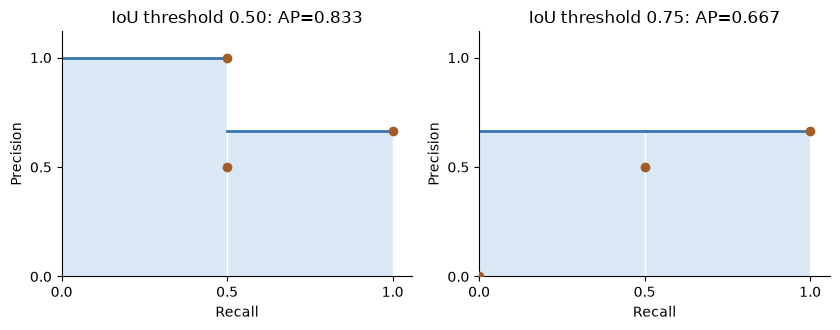

In [12]:
fig,axes=plt.subplots(1,2,figsize=(8.5,3.4))
for ax,(threshold,(precision,recall)) in zip(axes,curves.items()):
    envelope=np.maximum.accumulate(precision[::-1])[::-1]
    left=0.
    for right,height in zip(recall,envelope):
        if right>left:
            ax.add_patch(Rectangle((left,0),right-left,height,facecolor="#D9E8F4",edgecolor="white"))
            ax.plot([left,right],[height,height],color="#3976AF",lw=2)
        left=right
    ax.scatter(recall,precision,color="#A25E27",zorder=3,label="Raw points")
    ap_value=all_points_ap(precision,recall)
    ax.set(xlim=(0,1.06),ylim=(0,1.12),xticks=[0,.5,1],
           yticks=[0,.5,1],xlabel="Recall",ylabel="Precision",
           title=f"IoU threshold {threshold:.2f}: AP={ap_value:.3f}")
    ax.spines[["top","right"]].set_visible(False)
fig.tight_layout();plt.show()

The left area is $5/6$ and the right area is $2/3$. At the stricter
threshold, the later precision $2/3$ supplies the envelope over both recall
increments. No trapezoidal interpolation is used. These are single-image,
single-class, single-threshold all-points values, not COCO AP averaged over
classes, IoU thresholds and its 101 recall samples.

## 9. Compare two prompting protocols (optional)

Use the same held-out images and reference instance masks in both protocols.
Save image ID, instance ID, class and reference mask. For annotated-box
prompts, use each instance's own annotated box. For detector-box prompts,
freeze the detector and its confidence cutoff using validation data and
generate boxes without consulting test annotations.

For evaluation, associate detector boxes to reference objects in descending
confidence order within image and class. One explicit policy accepts the
highest-IoU unused annotation when box IoU is at least 0.5. Record unmatched
predictions and annotations separately. This evaluator uses reference labels
to score predictions; it does not supply them to the detector.

Use the same segmenter, image preprocessing, coordinate conversion and
selection rule in both protocols. If several masks are returned, choose the
highest predicted mask-quality score with a fixed tie rule. Then measure
its IoU with the reference mask on the original image grid. Selecting the
highest measured IoU would use an oracle and answer a different question.

Report annotated-box mask IoU over all reference instances. Also compare
both protocols on the same subset with an accepted detector box, pairing
by instance ID. A mean difference on that subset isolates the prompt change
among found objects. The full annotated-box protocol measures segmentation
given the object's identity and location; it bypasses detection.

If there are two buses, the detector finds one, and its mask IoU is 0.8,
the detected-only mean is 0.8. Coverage is $1/2$, and the all-instance mean
with misses assigned zero is $(0.8+0)/2=0.4$. State the zero-for-miss rule
explicitly. Extra predictions do not appear in that reference-instance mean,
so report false positives separately, or supplement it with a complete
instance-segmentation metric. Never silently drop missed objects from the
end-to-end result. The fixture records these denominators; it does not run
a detector or segmenter.

In [13]:
reference_ids=("bus-A","bus-B")
matched_iou={"bus-A":.8}
extra_predictions=("unmatched-P3",)
detected_mean=np.mean(list(matched_iou.values()))
all_instance_mean=sum(matched_iou.get(i,0.) for i in reference_ids)/len(reference_ids)
coverage=len(matched_iou)/len(reference_ids)
assert (detected_mean,all_instance_mean,coverage)==(.8,.4,.5)
print("Detected-only mean:",detected_mean)
print("All-instance mean, misses = 0:",all_instance_mean)
print("Coverage:",coverage,"| missed instances:",len(reference_ids)-len(matched_iou))
print("Extra predictions, reported separately:",len(extra_predictions))

Detected-only mean: 0.8
All-instance mean, misses = 0: 0.4
Coverage: 0.5 | missed instances: 1
Extra predictions, reported separately: 1


## 10. Audit resized annotations (optional)

Record original width and height, actual resized dimensions, and all padding
amounts. Convert predictions from normalized or center-size form into corner
coordinates on the padded canvas when needed. With scales $s_x,s_y$ and
left/top padding $p_l,p_t$, invert an edge using
$$
 x=(x'-p_l)/s_x,\qquad y=(y'-p_t)/s_y.
$$
Apply the rule to both corners. Subtracting padding first matters: the offsets
are measured on the enlarged canvas. Use actual dimension ratios if rounding
changed the intended resize scale. Clip to original bounds if the scoring
protocol requires it, then validate retained boxes. Avoid unnecessary integer
rounding before measuring overlap.

Here the original image is $4\times3$ in width-by-height order. Resizing gives
$8\times6$. With left padding 1 and top padding 2 and no right/bottom padding,
the canvas is $9\times8$. Forward mapping multiplies by two and adds offsets:
$(1,0,3,2)$ becomes $(3,2,7,6)$. Correct inversion recovers the original box
and IoU 1. Division alone gives $(1.5,1,3.5,3)$. Its intersection with the
correct box has width 1.5 and height 1, hence area 1.5; each box has area 4.
IoU is $1.5/(4+4-1.5)=3/13$. The incorrect box is inside the original bounds,
so a bounds-only check would miss the error.

In [14]:
original=np.array([1.,0.,3.,2.]);offset=np.array([1.,2.,1.,2.]);scale=2.
canvas_box=original*scale+offset
restored=(canvas_box-offset)/scale
wrong=canvas_box/scale
np.testing.assert_array_equal(canvas_box,[3,2,7,6])
np.testing.assert_array_equal(restored,original)
np.testing.assert_allclose(box_iou(original,wrong),3/13)
print("Canvas box:",canvas_box)
print("Correct inverse:",restored,"IoU:",box_iou(original,restored))
print("Divide only:",wrong,"IoU:",round(box_iou(original,wrong),6))

Canvas box: [3. 2. 7. 6.]
Correct inverse: [1. 0. 3. 2.] IoU: 1.0
Divide only: [1.5 1.  3.5 3. ] IoU: 0.230769


For a mask, first map the output to the padded canvas according to the
checkpoint's postprocessing. Remove the padding and resize the image region
to the original grid. For discrete Boolean labels use nearest-neighbor
resampling. For continuous logits or probabilities, follow the checkpoint's
specified interpolation and foreground-threshold order.

As a tiny mask test, mark original pixel (row 1, column 2). Doubling each
axis creates a 2-by-2 block. With the padding it occupies rows 4-5 and
columns 5-6. Correct unpadding followed by nearest-neighbor downsampling
recovers exactly the original grid. Taking a same-sized crop from the wrong
origin can still return a 3-by-4 array while shifting its foreground pixel.
The fixture uses integer repetition and stride sampling to make this exact
nearest-neighbor example transparent; it is not a general image resizer.

In [15]:
original_mask=np.zeros((3,4),dtype=bool);original_mask[1,2]=True
resized_mask=np.repeat(np.repeat(original_mask,2,axis=0),2,axis=1)
canvas_mask=np.pad(resized_mask,((2,0),(1,0)))
restored_mask=canvas_mask[2:8,1:9][::2,::2]
wrong_mask=canvas_mask[:6,:8][::2,::2]
assert restored_mask.shape==wrong_mask.shape==original_mask.shape
np.testing.assert_array_equal(restored_mask,original_mask)
assert not np.array_equal(wrong_mask,original_mask)
print("Canvas foreground:",np.argwhere(canvas_mask).tolist())
print("Recovered foreground:",np.argwhere(restored_mask).tolist())
print("Wrong crop, same shape:",np.argwhere(wrong_mask).tolist())

Canvas foreground: [[4, 5], [4, 6], [5, 5], [5, 6]]
Recovered foreground: [[1, 2]]
Wrong crop, same shape: [[2, 3]]


## 11. Separate detection errors (optional)

Use a $21\times6$ image containing a car A, bus B, bicycle C, and bus D.
The four panels show the relevant portion of that same coordinate system.
Solid green boxes are annotations; dashed orange boxes are predictions.
Use IoU threshold 0.5 and confidence cutoff 0.4, with matching within class.

| Object and reference box | Predictions | Error |
|---|---|---|
| A: car $(1,1,4,4)$ | Exact car at 0.95; car $(2,1,5,4)$ at 0.45 | Duplicate |
| B: bus $(6,1,9,4)$ | Exact box labeled truck at 0.82 | Wrong class |
| C: bicycle $(12,1,15,4)$ | Bicycle $(10,1,13,4)$ at 0.76 | Misplaced box |
| D: bus $(17,1,20,4)$ | No candidate at any confidence | Missing instance |

For A, the exact box claims the annotation first. The duplicate's IoU is
$6/(9+9-6)=0.5$, but A is already used. For B, IoU 1 cannot compensate
for the wrong class: the truck prediction is a false positive and the bus
remains unmatched. For C, IoU is $3/(9+9-3)=0.2$, below the requirement;
the prediction is false positive and the bicycle is missed. For D, no
prediction exists to match.

Raising confidence from 0.4 to 0.5 removes the duplicate while keeping the
correct car. It cannot change truck to bus, repair the bicycle's location,
or invent D. A still-higher cutoff could hide the wrong predictions but
would leave their objects missed. Lowering confidence can recover an instance
only if a suitable candidate already exists below the cutoff; D has none.
In other datasets, raising confidence can also remove correct low-scoring
predictions. Inspect localization and class errors as well as the ranking.

Duplicate IoU: 0.5
Wrong-class box IoU: 1.0
Misplaced IoU: 0.2


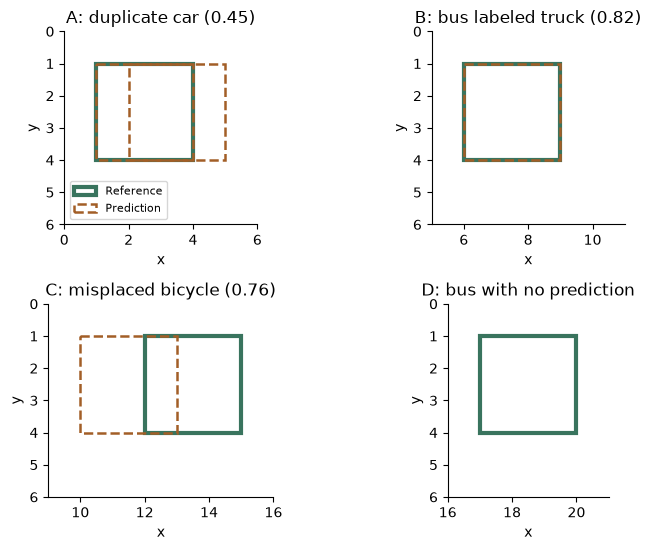

In [16]:
truth=[(1,1,4,4),(6,1,9,4),(12,1,15,4),(17,1,20,4)]
pred_boxes=[[(1,1,4,4),(2,1,5,4)],[(6,1,9,4)],[(10,1,13,4)],[]]
np.testing.assert_allclose(box_iou(truth[0],pred_boxes[0][1]),.5)
np.testing.assert_allclose(box_iou(truth[2],pred_boxes[2][0]),.2)
print("Duplicate IoU:",box_iou(truth[0],pred_boxes[0][1]))
print("Wrong-class box IoU:",box_iou(truth[1],pred_boxes[1][0]))
print("Misplaced IoU:",box_iou(truth[2],pred_boxes[2][0]))
fig,axes=plt.subplots(2,2,figsize=(8,5.6))
titles=["A: duplicate car (0.45)","B: bus labeled truck (0.82)","C: misplaced bicycle (0.76)","D: bus with no prediction"]
limits=[(0,6),(5,11),(9,16),(16,21)]
for ax,target,preds,title,xlim in zip(axes.flat,truth,pred_boxes,titles,limits):
    x0,y0,x1,y1=target
    ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,ec="#39745E",lw=3,label="Reference"))
    for j,(x0,y0,x1,y1) in enumerate(preds):
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,ec="#A25E27",lw=1.8,ls="--",label="Prediction" if j==0 else None))
    ax.set(xlim=xlim,ylim=(6,0),xlabel="x",ylabel="y",title=title)
    ax.set_aspect("equal");ax.spines[["top","right"]].set_visible(False)
axes[0,0].legend(loc="lower left",fontsize=8)
fig.tight_layout();plt.show()

Overlapping solid and dashed boundaries in B show that the coordinates
are correct while the class is wrong. D has no dashed box. The four errors
require different remedies; a single confidence threshold does not describe
or repair all of them. The drawing is a labeled synthetic audit fixture.